In this case study, we shall try to extract important information from resume. This case study usefulness is not limited to resume though, i.e., legal documents, stock documents, medical documents, etc.

We will be using two datasets; the first contains resume texts and the second contains skills that we will use to create an entity ruler.



### 1. Load Data


#### 1.1 Resume Dataset

Dataset is a collection of Resume Examples taken from livecareer.com for categorizing a given resume into any of the labels defined in the dataset.It Contains 2400+ Resumes in string as well as PDF format. (https://www.kaggle.com/datasets/snehaanbhawal/resume-dataset)

Features:
--------
- ID: Unique identifier and file name for the respective pdf.
- Resume_str : Contains the resume text only in string format.
- Resume_html : Contains the resume data in html format as present while web scrapping.
- Category : Category of the job the resume was used to apply.
    - HR, Designer, Information-Technology, Teacher, Advocate, Business-Development, Healthcare, Fitness, Agriculture, BPO, Sales, Consultant, Digital-Media, Automobile, Chef, Finance, Apparel, Engineering, Accountant, Construction, Public-Relations, Banking, Arts, Aviation


In [28]:
!python -m spacy download en_core_web_md

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.5/33.5 MB 24.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [32]:
!pip install PyPDF2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 232.6/232.6 kB 4.7 MB/s eta 0:00:00


#### Resumes Scraping:

```python

from bs4 import BeautifulSoup
import bs4
import requests
from selenium import webdriver

import pandas as pd
import numpy as np

import hashlib
import pdfkit   # !pip install pdfkit
import os

# USING selenium webdriver FOR WEB SCRAPPING
driver = webdriver.Chrome("chromedriver.exe")  

# LIST OF UNIQUE CATEGORIES THAT WAS NEEDED FOR THE DATASET. CUSTOMIZE AS NEEDED

job_list = ['HR', 'designer', 'Information-Technology',
       'Teacher', 'Advocate', 'Business-Development',
       'Healthcare', 'Fitness', 'Agriculture', 'BPO', 'Sales', 'Consultant',
       'Digital-Media', 'Automobile', 'Chef', 'Finance',
       'Apparel', 'Engineering', 'Accountant', 'Construction',
       'Public-Relations', 'Banking', 'Arts', 'Aviation']

# CREATING A DATAFRAME TO STORE THE LINKS OF EACH INDIVIDUAL RESUME EXAMPLE
resume_links = pd.DataFrame()
category = []
link = []

# LOOP TO SEARCH FOR RESUME EXAMPLES FROM THE WEBPAGE AS PER THE LABELS DEFINED ABOVE. ONLY (10*12) 120 RESUMES WILL BE COLLECTED.
# REMOVE  "&bg=85&eg=100&comp=&mod="  TO EXPAND THE SEARCH
# (bg=85 & eg=100) FILTERS THE RESUME BASED ON SCORE OF BETWEEEN 85 AND 100, INCREASE RANGE TO EXPAND SEARCH

for job in job_list:
    JOB = job.lower()
    for i in range(1, 13):   # INCREASE THE RANGE TO GET MORE RESUME DATA
        PAGE = str(i)
        URL = "https://www.livecareer.com/resume-search/search?jt=" + JOB + "&bg=85&eg=100&comp=&mod=&pg=" + PAGE
        driver.get(URL)
        aTagsInLi = driver.find_elements_by_css_selector('li a')
        for a in aTagsInLi:
            if a.get_attribute('rel') == "ugc":
                category.append(JOB)
                link.append(a.get_attribute('href'))

# STORES THE CATEGORY AND RESUME WEBPAGE LINK
resume_links["category"] = category
resume_links["link"] = link

# HASHES THE LINK AND CREATES AN UNIQUE ID FOR THE ROWS
def hash_id(link):
    return int(hashlib.md5(link.encode('utf-8')).hexdigest(), 16)

resume_links["id"] = resume_links["link"].apply(hash_id)

# PRINT THE NUMBER OF RESUME COLLECTED PER DEFINED LABELS
print(df.Category.value_counts())

df["resume_str"] = ""
df["resume_html"] = ""

# LOOP TO COLLECT THE RESUME DATA PRESENT IN THE LINKS COLECTED ABOVE AND STORE THEM IN HTML AS WELL AS STRING FORMAT

for i in range(df.shape[0]):
    url = df.link[i]
    driver.get(url)
#     time.sleep(0.5)                  #ADDED DELAY, CAN BE REMOVED
    x = driver.page_source
    x = x.replace(">","> ")
    soup = bs4.BeautifulSoup(x, 'html.parser')
    div = soup.find("div", {"id": "document"})
    df.resume_html[i] = div
    try:
        df.resume_str[i] = div.text
    except:
        pass

print(df.head())

# STORE THE DATAFRAME
df.to_csv("resume-dataset.csv",index=False)

# If you want to save the extracted resumes as pdfs : optional
df = pd.read_csv("resume-dataset.csv")
df = df.drop(['link'], axis=1)
df.dropna(inplace=True)
print(df.isnull().sum())

# SHORTENS THE ID
df.id = [x[::5] for x in df.id]

# Upper case the category
df.Category  = [x.upper() for x in df.Category]
labels = df.Category.unique()
print(df.head())
print(labels)
print(df.Category.value_counts())

# OVERWRITE THE CHANGES TO CSV
df.to_csv("resume-dataset.csv", index=False)

#SET A DIRECTORY PATH TO SAVE THE RESUME PDFS
parent_dir = ""

# LOOPS OVER THE DATAFRAME AND SAVES THE PDF WITH ID AS THE FILENAME
for label in labels:
    temp = df[df.Category == label]
    temp.dropna(inplace=True)
    temp.reset_index(inplace=True, drop=True)
    path = os.path.join(parent_dir, label)
    mode = 0o666
    os.mkdir(path, mode)
    os.chdir(path)
    for i in range(temp.shape[0]):
        pdfkit.from_string(temp.resume_html[i], temp.id[i]+".pdf")
```

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import kagglehub
import os
import shutil

# Download latest version
path = kagglehub.dataset_download("snehaanbhawal/resume-dataset")

print("Path to dataset files:", path)

drive_path = "/content/resume-data"
os.makedirs(drive_path, exist_ok=True)

shutil.copytree(path, drive_path, dirs_exist_ok=True)

print("Dataset saved to:", drive_path)

Path to dataset files: /kaggle/input/resume-dataset
Dataset saved to: /content/resume-data


In [3]:
import pandas as pd

resume_df = pd.read_csv("/content/resume-data/Resume/Resume.csv")

resume_df.head()

,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR


In [4]:
resume_df.Category.unique()

array(['HR', 'DESIGNER', 'INFORMATION-TECHNOLOGY', 'TEACHER', 'ADVOCATE',
       'BUSINESS-DEVELOPMENT', 'HEALTHCARE', 'FITNESS', 'AGRICULTURE',
       'BPO', 'SALES', 'CONSULTANT', 'DIGITAL-MEDIA', 'AUTOMOBILE',
       'CHEF', 'FINANCE', 'APPAREL', 'ENGINEERING', 'ACCOUNTANT',
       'CONSTRUCTION', 'PUBLIC-RELATIONS', 'BANKING', 'ARTS', 'AVIATION'],
      dtype=object)

In [5]:
resume_df.shape

(2484, 4)

In [6]:
resume_df["Category"].describe()

,Category
count,2484
unique,24
top,INFORMATION-TECHNOLOGY
freq,120


In [7]:
resume_df.Category.value_counts()

,count
Category,
INFORMATION-TECHNOLOGY,120
BUSINESS-DEVELOPMENT,120
ADVOCATE,118
CHEF,118
ENGINEERING,118
ACCOUNTANT,118
FINANCE,118
FITNESS,117
AVIATION,117


In [8]:
import numpy as np

# Randomize Job categories as they are in sequential order
resume_df = resume_df.reindex(np.random.permutation(resume_df.index))

# Sample just 200 resume as processing 2400+ takes time.
resume_df = resume_df.copy().iloc[0:200]

resume_df.shape

(200, 4)

In [9]:
resume_df.head()

,ID,Resume_str,Resume_html,Category
1241,17584743,OWNER/PRESIDENT Professiona...,"<div class=""fontsize fontface vmargins hmargin...",DIGITAL-MEDIA
908,90365216,SENIOR MEDICAL RECRUITER Su...,"<div class=""fontsize fontface vmargins hmargin...",FITNESS
550,13809698,PHLEBOTOMIST Professional Sum...,"<div class=""fontsize fontface vmargins hmargin...",ADVOCATE
556,17165107,HEALTH COACH www.linkedin....,"<div class=""fontsize fontface vmargins hmargin...",ADVOCATE
1849,13294301,ACCOUNTANT Professional Sum...,"<div class=""MPR skn-cbg1 fontsize fontface vma...",ACCOUNTANT


In [10]:
resume_df["Category"].describe()

,Category
count,200
unique,24
top,ACCOUNTANT
freq,15


In [11]:
# sample sentence
print(type(resume_df.Resume_str.values[:1]))
print(resume_df.Resume_str.values[:1].shape)
print(type(resume_df.Resume_str.values[:1][0]))

resume_df.Resume_str.values[:1][0]

<class 'numpy.ndarray'>
(1,)
<class 'str'>


'         OWNER/PRESIDENT           Professional Profile    A seasoned marketing professional who delivers results in alignment with strategic business plans by developing and executing marketing campaigns as well as managing external agencies.      Qualifications             Strategic marketing planning  Results measurement  Strategic development  Experiential customer events  Plan execution  NASCAR sponsorship  Video production      Execution of Webinars  Product positioning  Brand developmentIntegrated marketing communications  Account relations  Tactical planning            Relevant Experience     Oversaw campaign that exceeded annual goals and increased brand relevance with consumers/       Experience      Owner/President    January 2013   to   Current     Company Name          Freelance communications and digital content creation for corporate and independent businesses.  Development and production of video content for internet and social media.          Strategic Marketing Manag

#### 1.2 Load Data - Skill Patterns Dataset

The jobzilla skill dataset is jsonl file containing different skills that can be used to create spaCy `entity_ruler`. The data set contains label and pattern -> different words used to descibe skills in various resume

(https://github.com/kingabzpro/jobzilla_ai/blob/main/jz_skill_patterns.jsonl)

Note: jsonl stands for json lines, which allow processing line by line.

SpaCy EntityRuler can easily add patterns with input from jsonl directly using `from_disk`

In [12]:
import requests

url = "https://raw.githubusercontent.com/kingabzpro/jobzilla_ai/main/jz_skill_patterns.jsonl"
response = requests.get(url)

# Save the file
drive_path = "/content/skill-data"
os.makedirs(drive_path, exist_ok=True)

# Full path to save file in the desired directory
file_path = os.path.join(drive_path, "jz_skill_patterns.jsonl")
with open(file_path, "w", encoding='utf-8') as f:
    f.write(response.text)

print(f"File saved to: {file_path}")

File saved to: /content/skill-data/jz_skill_patterns.jsonl


In [14]:
import spacy

nlp = spacy.load("en_core_web_md")

ruler = nlp.add_pipe("entity_ruler")

ruler.from_disk("/content/skill-data/jz_skill_patterns.jsonl")  # contains labels and patterns

nlp.pipe_names  # notice entity ruler comes after ner, which is good for our particular usecase

['tok2vec',
 'tagger',
 'parser',
 'attribute_ruler',
 'lemmatizer',
 'ner',
 'entity_ruler']

### 2. Preprocessing

We are going o clean our dataset in a few steps:

- remove hyperlinks, special characters, or punctuations
- Lowering text
- Lemmatizing text to its base form for normalizations
- Removing English stopwords

In [20]:
from spacy.lang.en.stop_words import STOP_WORDS
import re

stopwords = list(STOP_WORDS)

def remove_hyperlinks(text):
    text = re.sub('(@[A-Za-z0-9]+)|([^0-9A-Za-z \t])|(\w+:\/\/\S+)|^rt|http.+?"', " ", text)
    return text

def preprocessing(text):
    text = remove_hyperlinks(text)
    clean_tokens = []
    doc = nlp(text)
    for token in doc:
        if token not in stopwords and token.pos_ not in ("PUNCT", "SPACE", "SYM"):
            clean_tokens.append(token.lemma_.lower().strip())
    return " ".join(clean_tokens)

In [21]:
# Test
remove_hyperlinks("this is my github - http://github.com/malla")

'this is my github    '

In [22]:
# Test
random_resume = resume_df.Resume_str.iloc[0]
print("---------------Original:---------------")
print(random_resume[:200])
print("---------------Preprocessed:---------------")
print(preprocessing(random_resume[:200]))

---------------Original:---------------
         OWNER/PRESIDENT           Professional Profile    A seasoned marketing professional who delivers results in alignment with strategic business plans by developing and executing marketing campa
---------------Preprocessed:---------------
owner president professional profile a season marketing professional who deliver result in alignment with strategic business plan by develop and execute marketing campa


In [23]:
# Let's preprocess all sentences
for idx, row in resume_df.iterrows():
    clean_text = preprocessing(row["Resume_str"])
    resume_df.at[idx, "Clean_resume"] = clean_text

In [ ]:
resume_df.head()

### 3. Information Extraction

Let's create a new feature in our dataframe called skill and extract skills from every resume row. This helps us visualize trends and patterns within the dataset.

In [26]:
def get_skills(text):
    doc = nlp(text)
    skills = []
    for ent in doc.ents:
        if ent.label_ == "SKILL":
            skills.append(ent.text)
    return skills

def unique_skills(skills):
    return list(set(skills))

resume_df["skills"] = resume_df["Clean_resume"].apply(get_skills)
resume_df["skills"] = resume_df.skills.apply(unique_skills)
resume_df.head()

,ID,Resume_str,Resume_html,Category,Clean_resume,skills
1241,17584743,OWNER/PRESIDENT Professiona...,"<div class=""fontsize fontface vmargins hmargin...",DIGITAL-MEDIA,owner president professional profile a season ...,"[medium, interaction, communications, tower, m..."
908,90365216,SENIOR MEDICAL RECRUITER Su...,"<div class=""fontsize fontface vmargins hmargin...",FITNESS,senior medical recruiter summary versatile res...,"[tracking system, business]"
550,13809698,PHLEBOTOMIST Professional Sum...,"<div class=""fontsize fontface vmargins hmargin...",ADVOCATE,phlebotomist professional summary reliable and...,"[windows, support, mobile, monitoring, testing]"
556,17165107,HEALTH COACH www.linkedin....,"<div class=""fontsize fontface vmargins hmargin...",ADVOCATE,health coach www linkedin com in caitlinmaska ...,"[medium, compose, support, marketing, material..."
1849,13294301,ACCOUNTANT Professional Sum...,"<div class=""MPR skn-cbg1 fontsize fontface vma...",ACCOUNTANT,accountant professional summary emerge account...,"[support, finance, accounting, business]"


### 4. Visualization

Lets visualize job and skills distribution.

In [28]:
# Jobs distribution
import plotly.express as px

fig = px.histogram(resume_df, x="Category", title="Distribution of Jobs Categories").update_xaxes(categoryorder="total descending")
fig.show()

#### Common skills in information technology

In [29]:
df_it = resume_df[resume_df.Category == "INFORMATION-TECHNOLOGY"]
df_it.shape  # 10 samples

(9, 6)

<BarContainer object of 10 artists>

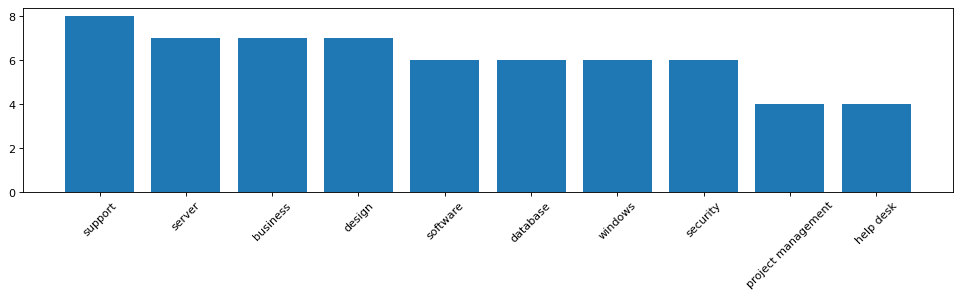

In [30]:
import numpy as np
from collections import Counter, OrderedDict
import matplotlib.pyplot as plt

# Combine all skills
all_skill_list = np.concatenate(df_it.skills.values)

counting = Counter(all_skill_list)
counting = OrderedDict(counting.most_common(10))

plt.figure(figsize=(15, 3), dpi=80)
plt.xticks(rotation = 45)
plt.bar(counting.keys(), counting.values())

### 5. Entity Recognition

In [31]:
from spacy import displacy

doc = nlp(resume_df.Clean_resume.iloc[0])

colors = {"SKILL": "linear-gradient(90deg, #aa9cfc, #fc9ce7)"}
options = {"colors": colors}
displacy.render(doc, style="ent", jupyter=True, options=options)

### 6. Real time inference

In [35]:
from PyPDF2 import PdfReader
from spacy import displacy

reader = PdfReader("/content/sample_resume.pdf")
page = reader.pages[0]  # first page just for demo
text = page.extract_text()

text = preprocessing(text)

doc = nlp(text)
colors = {"SKILL": "linear-gradient(90deg, #aa9cfc, #fc9ce7)"}
options = {"colors": colors}
displacy.render(doc, style="ent", jupyter=True, options=options)